In [ ]:
#Meshal Mahnoor

In [ ]:
#imports:
import os, urllib.request
import cv2
import numpy as np
import matplotlib.pyplot as plt

i)
**Observations:**
Video loaded and metadata shown

In [ ]:
video_path = "mishal.avi"
video_url = ("https://raw.githubusercontent.com/opencv/opencv/4.x/"
"samples/data/vtest.avi")
if not os.path.exists(video_path):
  try:
    urllib.request.urlretrieve(video_url, video_path)
  except Exception as e:
   print("Automatic download failed:", e)

cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
 cap.release()
 print("Upload a video file such as vtest.avi or traffic.mp4.")
try:
  from google.colab import files
  uploaded = files.upload()
  video_files = [n for n in uploaded if n.lower().endswith((".mp4", ".avi", ".mov", ".mkv"))]
  if not video_files:
   raise ValueError("No supported video file was uploaded.")
  video_path = video_files[0]
except ImportError:
  raise RuntimeError("Place a video file next to the notebook and set VIDEO_PATH.")
cap = cv2.VideoCapture(video_path)
if not cap.isOpened():
   raise RuntimeError(f"Could not open {video_path}.")

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap.release()

print(f"Video: {video_path}")
print(f"Resolution: {width} x {height}")
print(f"FPS: {fps:.2f}")
print(f"Number of frames: {frame_count}")
print(f"Duration: {frame_count / fps:.2f} seconds" if fps > 0 else "Duration: unknown")

Saving IMG_8792.mp4 to IMG_8792.mp4
Video: IMG_8792.mp4
Resolution: 1280 x 720
FPS: 30.01
Number of frames: 213
Duration: 7.10 seconds


ii) **Observations:**
6 frames loaded from 20 uptil 70

Frame dimensions: (360, 640)
Frames loaded successfully: True


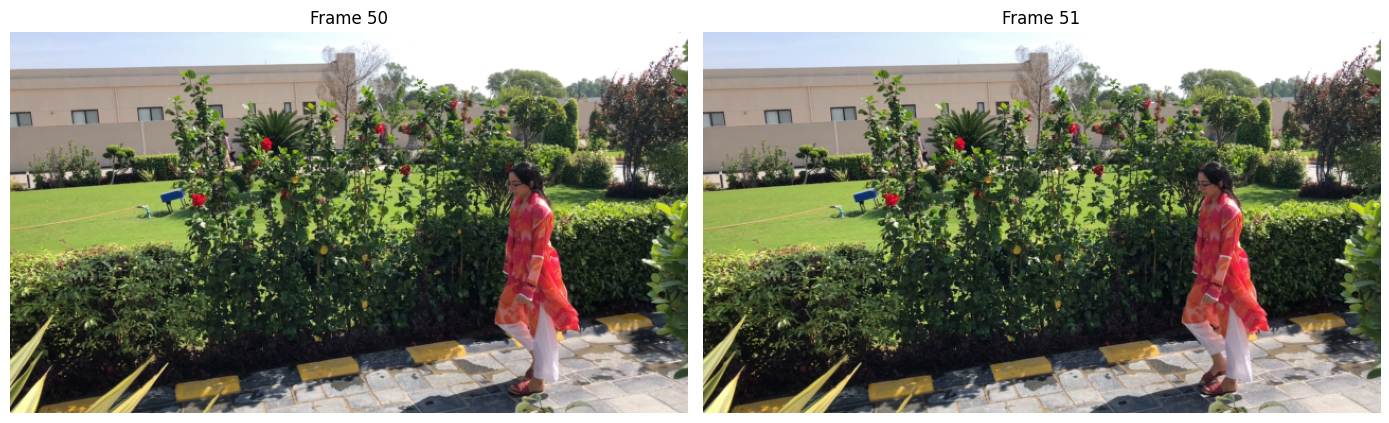

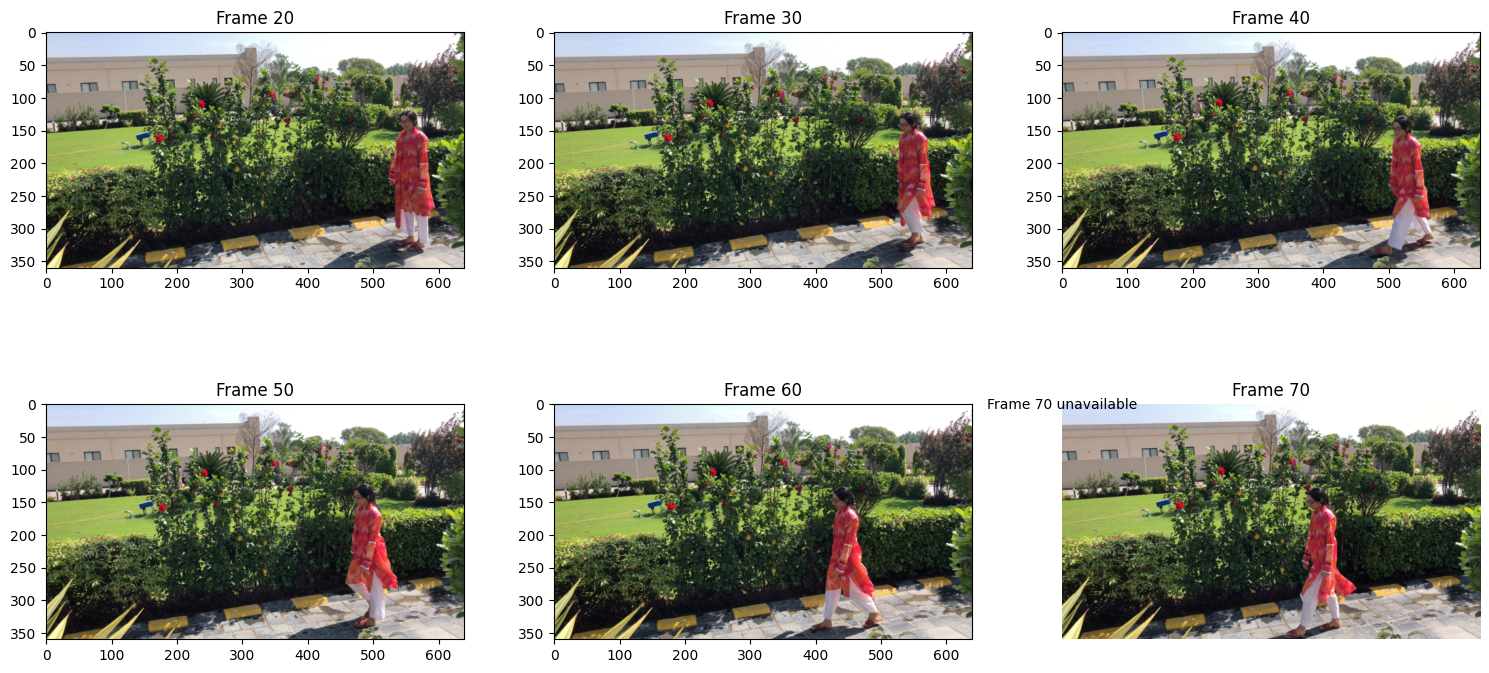

In [ ]:
cap = cv2.VideoCapture(video_path)
FRAME_INDEX = 50
# Read Frame 30
cap.set(cv2.CAP_PROP_POS_FRAMES, FRAME_INDEX)
ret1, frame1_bgr = cap.read()
# Read Frame 31
ret2, frame2_bgr = cap.read()
cap.release()
if not ret1 or not ret2:
 raise RuntimeError(
"Could not read the selected frame pair. "
"Choose a smaller FRAME_INDEX."
)
# RESIZE BOTH FRAMES TO THE SAME DIMENSIONS
target_width = 640
scale = min(1.0, target_width / frame1_bgr.shape[1])
new_size = (
int(frame1_bgr.shape[1] * scale),
int(frame1_bgr.shape[0] * scale)
)
frame1_bgr = cv2.resize(frame1_bgr, new_size)
frame2_bgr = cv2.resize(frame2_bgr, new_size)
# Convert BGR to RGB
frame1 = cv2.cvtColor(frame1_bgr, cv2.COLOR_BGR2RGB)
frame2 = cv2.cvtColor(frame2_bgr, cv2.COLOR_BGR2RGB)
# Convert RGB to grayscale
gray1 = cv2.cvtColor(frame1, cv2.COLOR_RGB2GRAY)
gray2 = cv2.cvtColor(frame2, cv2.COLOR_RGB2GRAY)
H, W = gray1.shape

print("Frame dimensions:", gray1.shape)
print("Frames loaded successfully:", gray1.shape == gray2.shape)

# DISPLAY CONSECUTIVE FRAMES IN CORRECT ORDER
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].imshow(frame1)
axes[0].set_title(f"Frame {FRAME_INDEX}")
axes[0].axis("off")
axes[1].imshow(frame2)
axes[1].set_title(f"Frame {FRAME_INDEX + 1}")
axes[1].axis("off")
plt.tight_layout()
plt.show()
# DISPLAY A CHRONOLOGICAL SEQUENCE OF FRAMES
# Frame 10 -> Frame 20 -> Frame 30 -> Frame 40 -> ...
indices = [20, 30, 40, 50,60,70]
cap = cv2.VideoCapture(video_path)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
# Flatten axes so frames are assigned in sequential order
axes = axes.flatten()
for i, idx in enumerate(indices):
# Seek to the requested frame number
 cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
 ret, fr_bgr = cap.read()
 if ret:
  # Resize and convert to RGB
  fr_bgr = cv2.resize(fr_bgr, new_size)
  fr_rgb = cv2.cvtColor(fr_bgr, cv2.COLOR_BGR2RGB)
  axes[i].imshow(fr_rgb)
  axes[i].set_title(f"Frame {idx}", fontsize=12)
else:
  axes[i].text(
 0.5, 0.5,
f"Frame {idx} unavailable",
ha="center",
va="center"
)
  axes[i].set_title(f"Frame {idx}")
axes[i].axis("off")
cap.release()
# Keep the subplot arrangement fixed: left-to-right, top-to-bottom
plt.tight_layout()
plt.show()

iii)**Observations:**
TX is 460 and TY is 200, The SSD and SAD values are same (-4,0)

SSD best translation (dx, dy): (-4, 0)  minimum mean SSD: 394.3
SAD best translation (dx, dy): (-4, 0)  minimum mean SAD: 10.9
Error with no motion (0, 0): SSD = 1204.6 SAD = 23.7


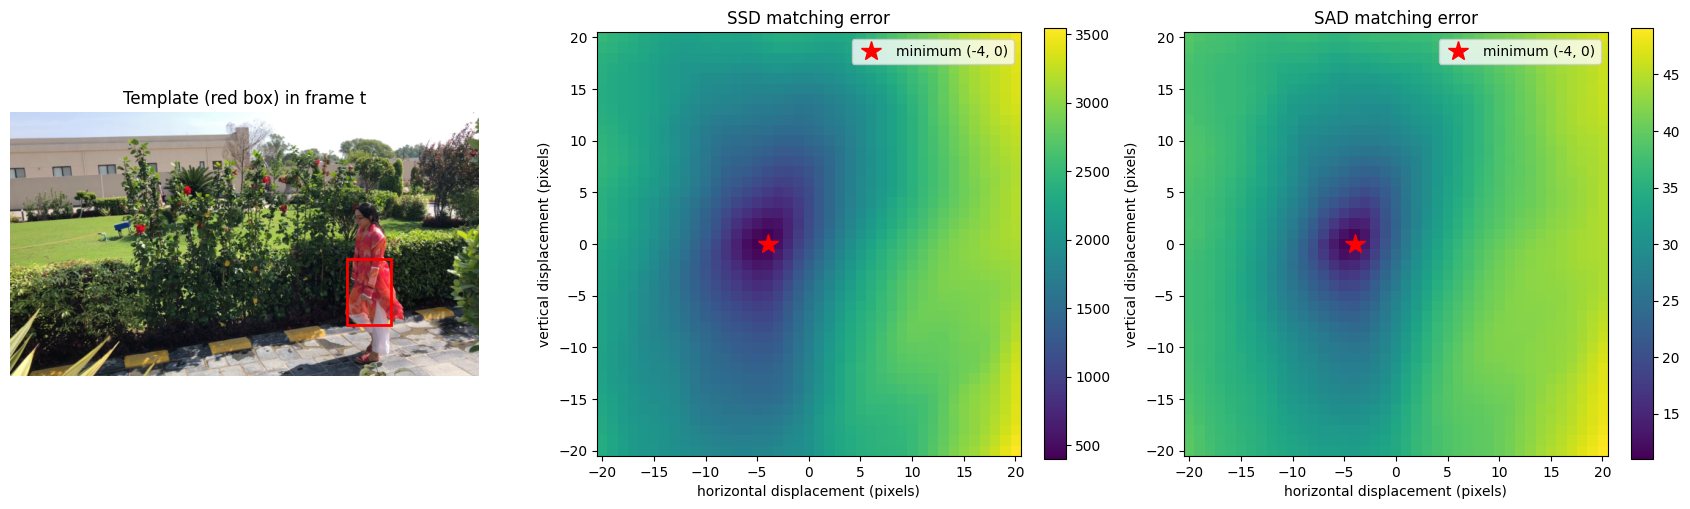

In [ ]:
# Template: box around the two pedestrians on the right (x, y, width, height)
TX, TY, TW, TH = 460, 200, 60, 90
R = 20  # search range:0The template can move up to 20 pixels left, right, up, or down.


def calculate_matching_errors(img1, img2, x, y, w, h, R):
    # Slide the template containing pedestrians we want to track from img1 over img2 and return mean
    # SSD / SAD maps.
    T = img1[y : y + h, x : x + w].astype(np.float32)

    # Create an empty SSD error map of size 41 x 41, cells store matching error for one displacement (dx, dy)
    ssd = np.full((2 * R + 1, 2 * R + 1), np.nan, np.float32)

    # Create a second 41 x 41 map to store SAD errors.
    sad = np.full_like(ssd, np.nan)

    # Try every possible vertical displacement from "-20" to +20 pixels.
    for dy in range(-R, R + 1):
        # For each vertical displacement, try every horizontal displacement.
        for dx in range(-R, R + 1):
            # Calculate the candidate template's top-left position in frame 2.
            # dx shifts the template horizontally, dy shifts the template vertically.
            xx, yy = x + dx, y + dy

            # Check whether the entire candidate template fits inside frame 2.
            # If any part falls outside the image, skip this displacement.
            if (
                xx < 0
                or yy < 0
                or xx + w > img2.shape[1]
                or yy + h > img2.shape[0]
            ):
                continue

            # Extract a candidate patch from frame 2 at the current position.
            P = img2[yy : yy + h, xx : xx + w].astype(np.float32)

            # Calculate the pixel-by-pixel difference between the candidate
            e = P - T

            # Store the result at the map location corresponding to (dx, dy).
            ssd[dy + R, dx + R] = np.mean(e**2)  # SSD / area
            sad[dy + R, dx + R] = np.mean(np.abs(e))  # SAD / area

    return ssd, sad


def best(err):
    # Find the row and column containing the smallest valid error.
    iy, ix = np.unravel_index(np.nanargmin(err), err.shape)

    # Convert the map's row and column back into displacement coordinates.
    # The center of the map represents (dx, dy) = (0, 0).
    # Subtracting R converts map indices into actual pixel displacements.
    # Return horizontal displacement first and vertical displacement second
    return int(ix - R), int(iy - R)


ssd_map, sad_map = calculate_matching_errors(gray1, gray2, TX, TY, TW, TH, R)
u_ssd, u_sad = best(ssd_map), best(sad_map)

print(
    "SSD best translation (dx, dy):",
    u_ssd,
    f" minimum mean SSD: {np.nanmin(ssd_map):.1f}",
)
print(
    "SAD best translation (dx, dy):",
    u_sad,
    f" minimum mean SAD: {np.nanmin(sad_map):.1f}",
)
print(
    f"Error with no motion (0, 0): SSD = {ssd_map[R, R]:.1f} SAD = {sad_map[R, R]:.1f}"
)

fig, ax = plt.subplots(1, 3, figsize=(17, 5))
ax[0].imshow(frame1)
ax[0].add_patch(
    plt.Rectangle((TX, TY), TW, TH, fill=False, ec="red", lw=2)
)
ax[0].set_title("Template (red box) in frame t")
ax[0].axis("off")

for a, m, name, b in [
    (ax[1], ssd_map, "SSD", u_ssd),
    (ax[2], sad_map, "SAD", u_sad),
]:
    im = a.imshow(
        m, origin="lower", extent=(-R - 0.5, R + 0.5, -R - 0.5, R + 0.5)
    )
    a.plot(*b, "r*", ms=15, label=f"minimum {b}")
    a.set_xlabel("horizontal displacement (pixels)")
    a.set_ylabel("vertical displacement (pixels)")
    a.set_title(f"{name} matching error")
    a.legend()
    plt.colorbar(im, ax=a, fraction=0.046)

plt.tight_layout()
plt.show()


iv) **Observations:**
For solving for (u,v) we need Ix, Iy and It.

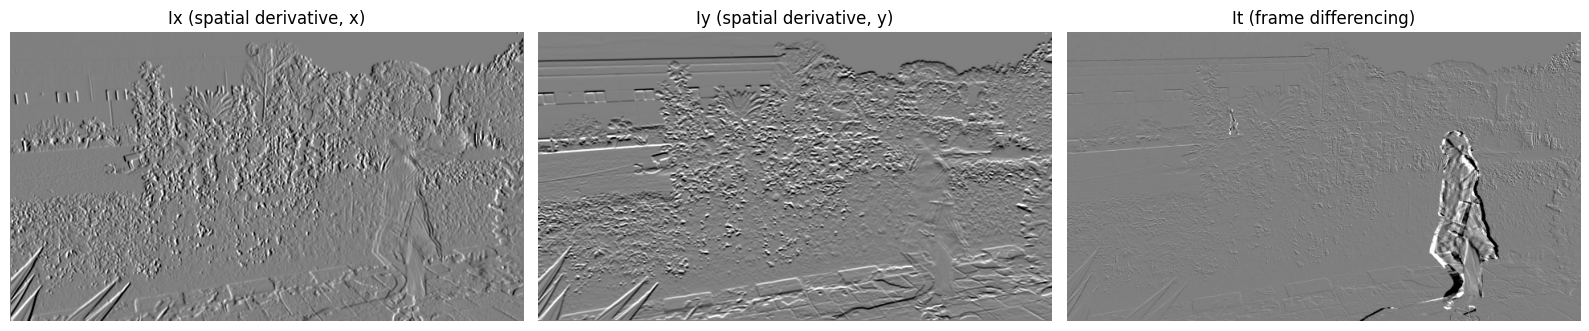

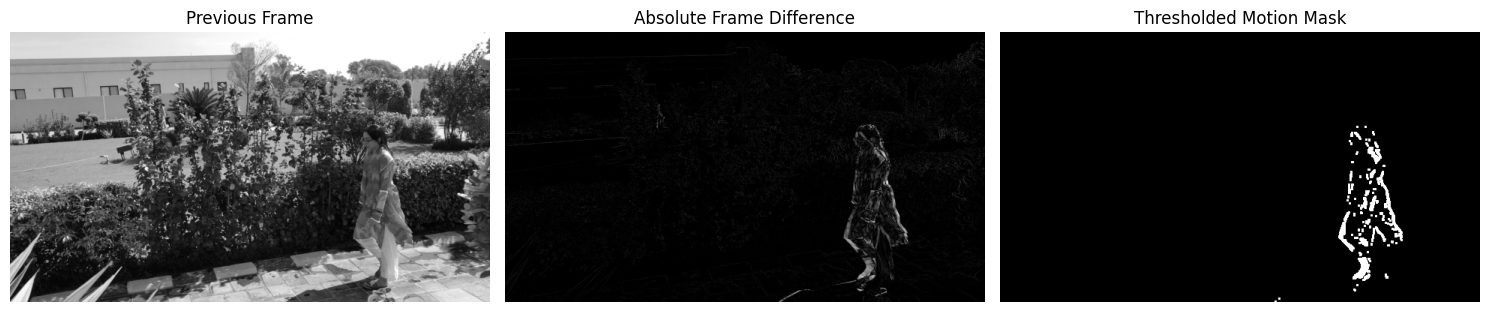

Changed pixels: 3158
Changed pixel percentage: 1.37%


In [ ]:
def image_derivatives(I1, I2):
    # Convert frames to float32 to support negative and fractional values.
    I1 = I1.astype(np.float32)
    I2 = I2.astype(np.float32)

    # Compute and average (*0.5) horizontal Sobel gradients from both frames; /8 normalizes the response.
    Ix = (
        0.5
        * (
            cv2.Sobel(I1, cv2.CV_32F, 1, 0, ksize=3)
            + cv2.Sobel(I2, cv2.CV_32F, 1, 0, ksize=3)
        )
        / 8.0
    )

    # Compute and average vertical Sobel gradients from both frames; /8 normalizes the response.
    Iy = (
        0.5
        * (
            cv2.Sobel(I1, cv2.CV_32F, 0, 1, ksize=3)
            + cv2.Sobel(I2, cv2.CV_32F, 0, 1, ksize=3)
        )
        / 8.0
    )

    # Subtract consecutive frames to measure temporal intensity changes.
    It = I2 - I1

    # Return horizontal, vertical, and temporal derivatives.
    return Ix, Iy, It


# Calculate spatial and temporal derivatives for the two frames.
Ix, Iy, It = image_derivatives(gray1, gray2)

# Create three side-by-side plots for the derivative images.
plt.figure(figsize=(16, 4.5))

# Display each derivative using a separate subplot.
for i, (img, name) in enumerate(
    [
        (Ix, "Ix (spatial derivative, x)"),
        (Iy, "Iy (spatial derivative, y)"),
        (It, "It (frame differencing)"),
    ]
):
    # Use the 99.5th percentile of absolute values to limit display contrast.
    lim = np.percentile(np.abs(img), 99.5)

    # Display positive and negative derivative values using a symmetric grayscale range.
    plt.subplot(1, 3, i + 1)
    plt.imshow(img, cmap="gray", vmin=-lim, vmax=lim)
    plt.title(name)
    plt.axis("off")

# Adjust subplot spacing and display the derivative images.
plt.tight_layout()
plt.show()

# Calculate absolute pixel differences between consecutive frames.
difference = cv2.absdiff(gray1, gray2)

# Mark pixels with intensity differences greater than 20 as white; others become black.
_, motion_mask = cv2.threshold(difference, 20, 255, cv2.THRESH_BINARY)

# Remove small isolated white regions using 3x3 morphological opening.
motion_mask_clean = cv2.morphologyEx(
    motion_mask, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8)
)

# Create three plots to compare the previous frame, differences, and motion mask.
plt.figure(figsize=(15, 5))

# Display the previous grayscale frame.
plt.subplot(1, 3, 1)
plt.imshow(gray1, cmap="gray")
plt.title("Previous Frame")
plt.axis("off")

# Display absolute intensity differences; brighter pixels indicate larger changes.
plt.subplot(1, 3, 2)
plt.imshow(difference, cmap="gray")
plt.title("Absolute Frame Difference")
plt.axis("off")

# Display the cleaned binary mask; white pixels represent detected intensity changes.
plt.subplot(1, 3, 3)
plt.imshow(motion_mask_clean, cmap="gray")
plt.title("Thresholded Motion Mask")
plt.axis("off")

# Adjust spacing and display all three images.
plt.tight_layout()
plt.show()

# Count the pixels classified as changed in the cleaned motion mask.
changed = np.count_nonzero(motion_mask_clean)

# Print the number and percentage of changed pixels in the image.
print("Changed pixels:", changed)
print(f"Changed pixel percentage: {100 * changed / motion_mask_clean.size:.2f}%")


Least-squares flow (small image): u = -1.32, v = 0.21
Scaled to full resolution: u = -5.3, v = 0.8 (SSD gave (-4, 0))


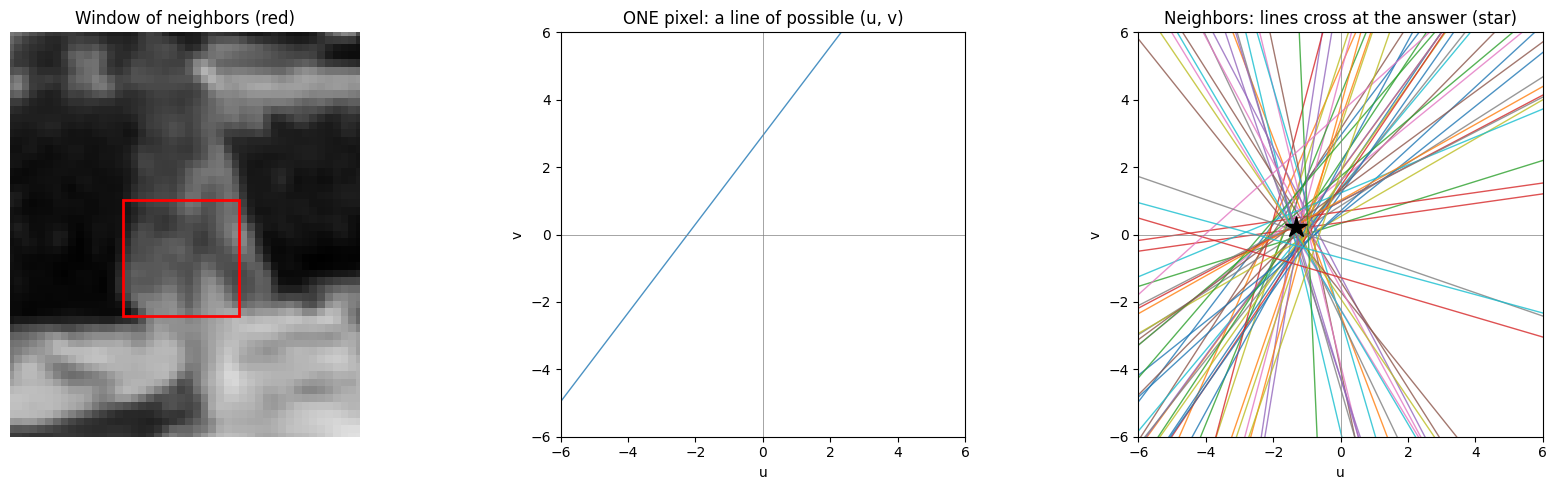

In [ ]:
# Set the downsampling factor to reduce image size and apparent motion.
S = 4


def shrink(g):
    # Reduce image dimensions by a factor of 4 using area interpolation.
    small = cv2.resize(
        g, None, fx=1 / S, fy=1 / S, interpolation=cv2.INTER_AREA
    )
    # Smooth the resized image to reduce noise and return floating-point pixels.
    return cv2.GaussianBlur(small, (3, 3), 0.8).astype(np.float32)


# Downsample and smooth both frames.
A, B = shrink(gray1), shrink(gray2)

# Calculate spatial and temporal derivatives on the smaller images.
Ix_s, Iy_s, It_s = image_derivatives(A, B)

# Convert the original pedestrian template coordinates to the smaller image.
bx, by, bw, bh = TX // S, TY // S, TW // S, TH // S

# Set the window radius to 7 pixels, giving a 15 x 15 neighborhood.
r = 7


def window_tensor(cx, cy):
    # Select a 15 x 15 window centered at (cx, cy).
    s = (slice(cy - r, cy + r + 1), slice(cx - r, cx + r + 1))
    # Extract and flatten horizontal and vertical gradients within the window.
    ix, iy = Ix_s[s].ravel(), Iy_s[s].ravel()
    # Build the structure tensor and return its smaller eigenvalue.
    # A larger smaller eigenvalue indicates stronger gradients in multiple directions.
    return np.linalg.eigvalsh([[ix @ ix, ix @ iy], [ix @ iy, iy @ iy]])[0]


# Generate candidate window centers fully contained within the pedestrian region.
cands = [
    (cx, cy)
    for cy in range(by + r, by + bh - r)
    for cx in range(bx + r, bx + bw - r)
]

# Select the window with the largest smaller eigenvalue.
# This favors regions with informative gradients in more than one direction.
cx, cy = max(cands, key=lambda p: window_tensor(*p))

# Extract the spatial and temporal derivatives inside the selected window.
s = (slice(cy - r, cy + r + 1), slice(cx - r, cx + r + 1))
ix, iy, it = Ix_s[s].ravel(), Iy_s[s].ravel(), It_s[s].ravel()

# Solve Ix*u + Iy*v = -It using least squares across all window pixels.
# Combining multiple pixels estimates one shared horizontal and vertical flow.
(u_lk, v_lk), *_ = np.linalg.lstsq(np.stack([ix, iy], 1), -it, rcond=None)

# Print the estimated flow in the downsampled image coordinates.
print(f"Least-squares flow (small image): u = {u_lk:.2f}, v = {v_lk:.2f}")

# Multiply by the shrink factor to express the estimated flow in original pixels.
# Compare the result with the SSD displacement estimate.
print(
    f"Scaled to full resolution: u = {u_lk * S:.1f}, v = {v_lk * S:.1f} (SSD gave {u_ssd})"
)


def draw_lines(ax, ix, iy, it, lim=6, n=60):
    # Define the plotting range for horizontal and vertical flow components.
    t = np.array([-lim, lim])
    # Select up to n pixels with the strongest spatial gradients.
    for k in np.argsort(-np.hypot(ix, iy))[:n]:
        # Retrieve the horizontal gradient, vertical gradient, and temporal derivative.
        a, b, d = ix[k], iy[k], it[k]
        # Plot the constraint line a*u + b*v = -d.
        # Choose the equation form that avoids dividing by the smaller coefficient.
        if abs(b) >= abs(a):
            ax.plot(t, -(d + a * t) / b, lw=1, alpha=0.8)
        else:
            ax.plot(-(d + b * t) / a, t, lw=1, alpha=0.8)
    # Draw reference axes at zero flow.
    ax.axhline(0, color="gray", lw=0.5)
    ax.axvline(0, color="gray", lw=0.5)
    # Set equal scales and limits for horizontal and vertical flow.
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    # Label the flow components.
    ax.set_xlabel("u")
    ax.set_ylabel("v")


# Find the window pixel with the strongest spatial gradient.
k1 = np.argmax(np.hypot(ix, iy))

# Create three plots to illustrate the optical-flow constraints.
fig, ax = plt.subplots(1, 3, figsize=(17, 5))

# Display the downsampled image and mark the selected 15 x 15 window.
ax[0].imshow(A, cmap="gray")
ax[0].add_patch(
    plt.Rectangle(
        (cx - r - 0.5, cy - r - 0.5),
        2 * r + 1,
        2 * r + 1,
        fill=False,
        ec="red",
        lw=2,
    )
)
ax[0].set_xlim(bx - 15, bx + bw + 15)
ax[0].set_ylim(by + bh + 15, by - 15)
ax[0].set_title("Window of neighbors (red)")
ax[0].axis("off")

# Plot the flow constraint from one pixel.
# One equation gives a line of possible (u, v) values, not a unique solution.
draw_lines(ax[1], ix[[k1]], iy[[k1]], it[[k1]])
ax[1].set_title("ONE pixel: a line of possible (u, v)")

# Plot constraint lines from all selected window pixels.
# Their approximate intersection indicates the least-squares flow estimate.
draw_lines(ax[2], ix, iy, it)
ax[2].plot(u_lk, v_lk, "k*", ms=16)
ax[2].set_title("Neighbors: lines cross at the answer (star)")

# Adjust subplot spacing and display all three plots.
plt.tight_layout()
plt.show()


v) **Observations:** Tracking points using sparse lucas-Kanade, meaning there is a threshold of pixels to consider.

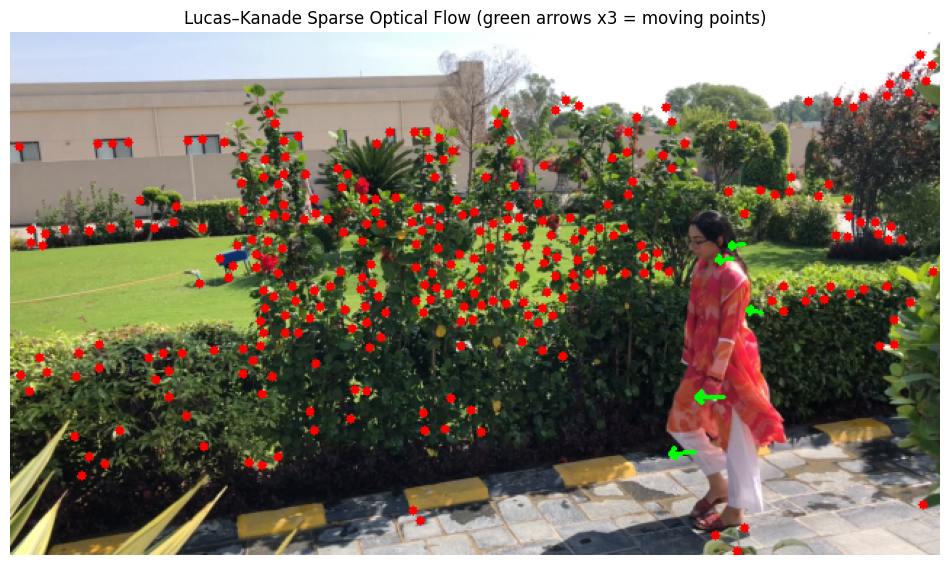

Initially detected features: 300
Successfully tracked points: 300
Moving points: 5  Static points: 295
Mean displacement of moving points (u, v): [-4.45  0.06]


In [ ]:
# Detect up to 300 strong corner features in the first grayscale frame.
# qualityLevel sets the minimum accepted corner strength relative to the strongest corner.
# minDistance enforces at least 8 pixels between detected features.
# blockSize specifies the neighborhood used to calculate corner quality.
features = cv2.goodFeaturesToTrack(gray1, maxCorners=300, qualityLevel=0.01, minDistance=8,
blockSize=7)
# Stop execution if no trackable features were detected.
if features is None or len(features) == 0:
 raise RuntimeError("No trackable features were detected. Try another frame pair.")
# Track the detected features from the first frame to the second using pyramidal Lucas–Kanade optical flow.
# winSize defines the local search window; maxLevel=3 allows a pyramid with up to 3 additional levels.
# criteria stops the iterative search after 30 iterations or when the change falls below 0.01.
next_points, status, errors = cv2.calcOpticalFlowPyrLK(
gray1, gray2, features, None, winSize=(21, 21), maxLevel=3,
criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 30, 0.01))
# Keep only points that Lucas–Kanade successfully tracked.
valid = status.ravel() == 1
# Extract the original positions of successfully tracked features.
good_old = features.reshape(-1, 2)[valid]
# Extract their corresponding positions in the second frame.
good_new = next_points.reshape(-1, 2)[valid]
# Calculate each tracked feature's horizontal and vertical displacement (u, v).
vectors = good_new - good_old
# Classify points with displacement greater than 1.5 pixels as moving.
moving = np.linalg.norm(vectors, axis=1) > 1.5
# Copy the second frame to draw the optical-flow results without altering the original.
output_sparse = frame2.copy()
# Set the arrow-length amplification factor for easier visualization.
GAIN = 3

# Process each tracked point, its new position, and its movement classification.
for (x1, y1), (x2, y2), mv in zip(good_old, good_new, moving):
# If the displacement exceeds the threshold, draw an amplified green arrow.
 if mv:
  end = (int(round(x1 + GAIN * (x2 - x1))), int(round(y1 + GAIN * (y2 - y1))))
  cv2.arrowedLine(output_sparse, (int(x1), int(y1)), end, (0, 255, 0), 2, tipLength=0.3)
# Otherwise, mark the point as approximately static with a blue circle.
 else:
  cv2.circle(output_sparse, (int(x1), int(y1)), 3, (255, 0, 0), -1)
# Display the second frame with green motion arrows and blue static-point markers.
plt.figure(figsize=(12, 7))
plt.imshow(output_sparse)
plt.title("Lucas–Kanade Sparse Optical Flow (green arrows x3 = moving points)")
plt.axis("off")
plt.show()
# Print the total number of features detected in the first frame.
print("Initially detected features:", len(features))
# Print how many detected features were successfully tracked in the second frame.
print("Successfully tracked points:", int(valid.sum()))
# Print the counts of points classified as moving and approximately static.
print("Moving points:", int(moving.sum()), " Static points:", int((~moving).sum()))
# Calculate and print the mean horizontal and vertical displacement of moving points.
print("Mean displacement of moving points (u, v):", np.round(vectors[moving].mean(0), 2))

vi) **Observations:**
Dense flow computed with Farneback (all pixels considered)

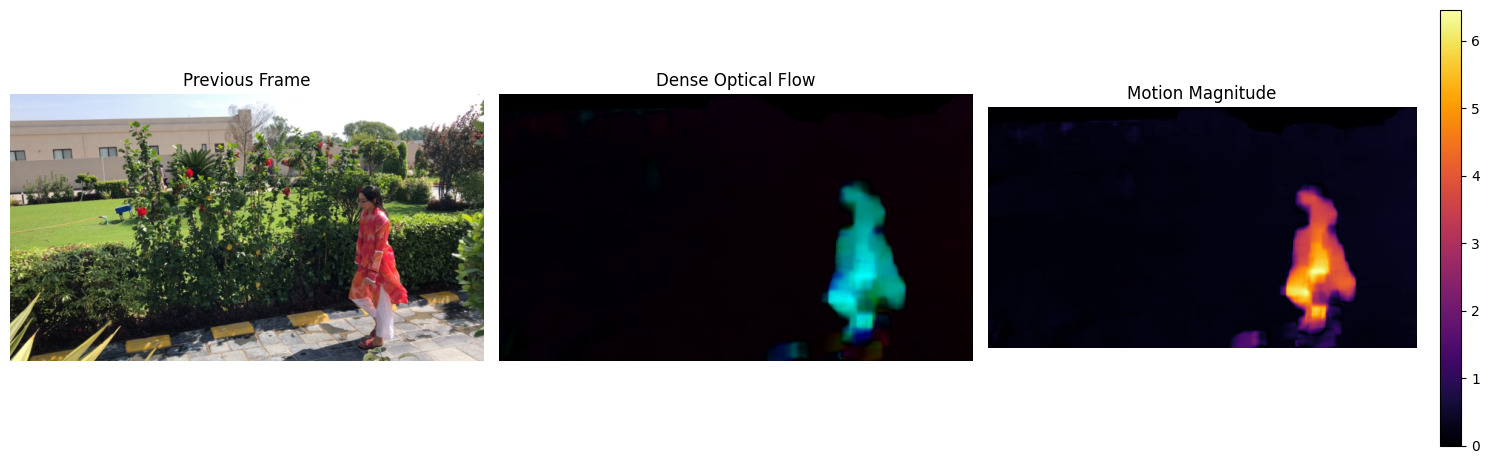

Mean flow magnitude: 0.417
Maximum flow magnitude: 6.459


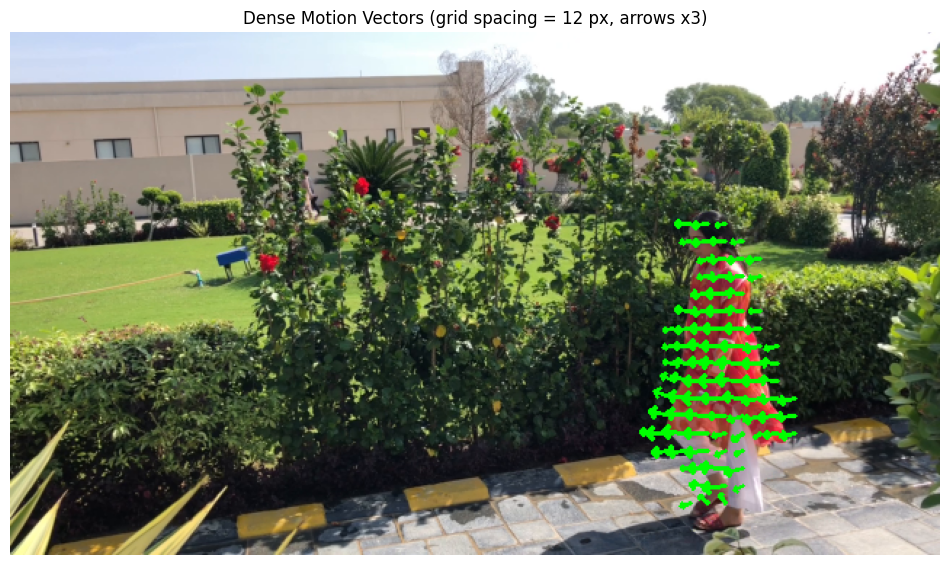

In [ ]:
# Calculate dense optical flow between the previous and next grayscale frames.
flow = cv2.calcOpticalFlowFarneback(gray1, gray2, None, pyr_scale=0.5, levels=3, winsize=21,
iterations=3, poly_n=5, poly_sigma=1.2, flags=0)
# Extract horizontal and vertical motion components from the flow field.
flow_x, flow_y = flow[..., 0], flow[..., 1]
# Calculate each pixel's motion magnitude and direction angle.
magnitude, angle = cv2.cartToPolar(flow_x, flow_y)
# Create an HSV image to visualize motion direction and magnitude using color.
hsv = np.zeros((*gray1.shape, 3), np.uint8)
# Encode motion direction as hue, mapping angles from 0 to 2π into OpenCV's hue range.
hsv[..., 0] = (angle * 90 / np.pi).astype(np.uint8)
# Set saturation to maximum so motion directions appear in vivid colors.
hsv[..., 1] = 255
# Normalize motion magnitudes to the range 0–255 for brightness visualization.
hsv[..., 2] = cv2.normalize(magnitude, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)
# Convert the HSV motion visualization into RGB format for Matplotlib.
flow_rgb = cv2.cvtColor(hsv, cv2.COLOR_HSV2RGB)
# Create three plots showing the original frame, dense flow, and motion magnitude.
plt.figure(figsize=(15, 5))
# Display the previous video frame as a reference.
plt.subplot(1, 3, 1)
plt.imshow(frame1)
plt.title("Previous Frame")
plt.axis("off")
# Display the dense optical-flow visualization.
# Color represents motion direction, while brightness represents relative magnitude.
plt.subplot(1, 3, 2)
plt.imshow(flow_rgb)
plt.title("Dense Optical Flow")
plt.axis("off")
# Display the magnitude map, where brighter regions indicate stronger estimated motion.
plt.subplot(1, 3, 3)
plt.imshow(magnitude, cmap="inferno")

plt.title("Motion Magnitude")
plt.colorbar(fraction=0.046)
plt.axis("off")
# Adjust subplot spacing and display all three visualizations.
plt.tight_layout()
plt.show()
# Print the average estimated motion magnitude across all pixels.
print("Mean flow magnitude:", round(float(magnitude.mean()), 3))
# Print the largest estimated motion magnitude in the flow field.
print("Maximum flow magnitude:", round(float(magnitude.max()), 3))
# Create a copy of the second frame for drawing motion vectors.
vector_image = frame2.copy()
# Set the grid spacing between arrows and amplify arrow lengths for visibility.
step, arrow_scale = 12, 3.0
# Sample the dense flow field at regularly spaced pixel locations.
for y in range(step, H - step, step):
 for x in range(step, W - step, step):
 # Retrieve the horizontal and vertical flow components at this pixel.
  dx, dy = flow[y, x]
# Draw arrows only for moderate motion magnitudes between 1.5 and 30 pixels.
# This excludes small movements and unusually large estimated displacements.
  if 1.5 < np.hypot(dx, dy) < 30:
# Draw a green arrow from the sampled pixel along its amplified motion vector.
   cv2.arrowedLine(vector_image, (x, y), (int(round(x + arrow_scale * dx)), int(round(y +
arrow_scale * dy))),
(0, 255, 0), 2, tipLength=0.3)
# Display the second frame overlaid with sampled dense motion vectors.
plt.figure(figsize=(12, 7))
plt.imshow(vector_image)
plt.title(f"Dense Motion Vectors (grid spacing = {step} px, arrows x{arrow_scale:g})")
plt.axis("off")
plt.show()

vii) **Observations:** The aplha value of 50 looks best because it detects the object moving (me) with most accuracy.

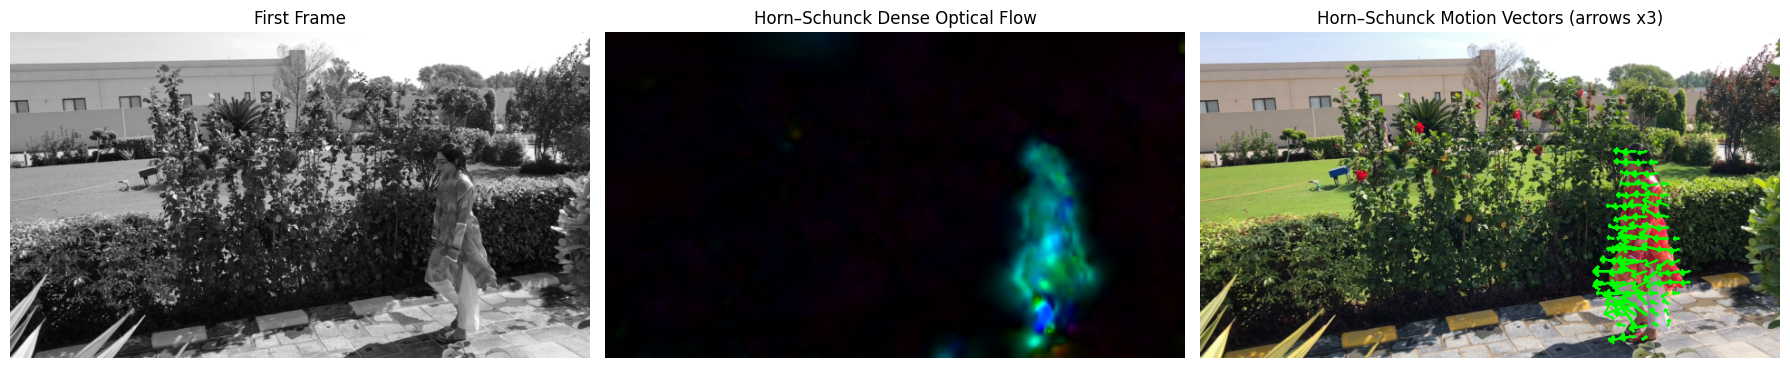

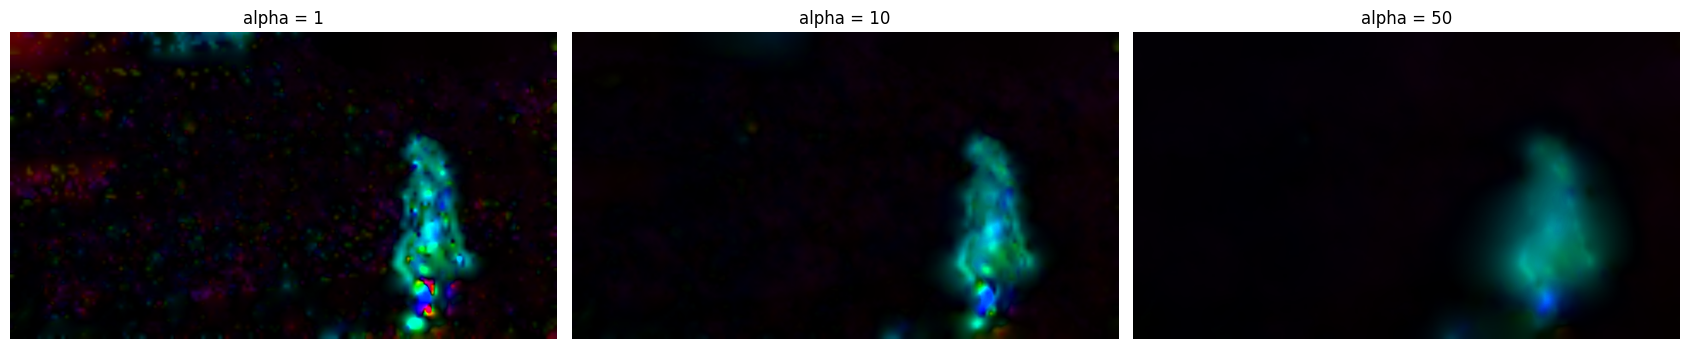

In [ ]:
def horn_schunck(I1, I2, alpha=10.0, iterations=300):
    # Horn–Schunck dense optical flow. alpha**2 = 1/lambda (smoothness weight).
    I1 = I1.astype(np.float32)
    I2 = I2.astype(np.float32)  # Convert both frames to 32-bit floating point

    # Steps 1 and 2: spatial and temporal gradients
    Ix, Iy, It = image_derivatives(
        I1, I2
    )  # Calculate horizontal, vertical, and temporal image gradients

    # Step 3: initialize the flow field
    u = np.zeros_like(I1)
    v = np.zeros_like(I1)  # Initialize horizontal and vertical flow components to zero

    # Weighted average of the 8 neighbors (centre excluded)
    avg = (
        np.array([[1, 2, 1], [2, 0, 2], [1, 2, 1]], np.float32) / 12.0
    )  # Define normalized weights for averaging neighboring flow values
    denominator = (
        alpha**2 + Ix**2 + Iy**2
    )  # Precompute the denominator used in each flow update

    # Step 4: iterate
    for _ in range(iterations):  # Repeatedly refine the flow estimates
        u_bar = cv2.filter2D(
            u, -1, avg, borderType=cv2.BORDER_REPLICATE
        )  # Compute the locally averaged horizontal flow
        v_bar = cv2.filter2D(
            v, -1, avg, borderType=cv2.BORDER_REPLICATE
        )  # Compute the locally averaged vertical flow
        correction = (
            Ix * u_bar + Iy * v_bar + It
        ) / denominator  # Calculate the correction from the optical-flow constraint
        u = u_bar - Ix * correction  # Update the horizontal flow estimate
        v = v_bar - Iy * correction  # Update the vertical flow estimate

    return u, v  # Return the estimated dense horizontal and vertical flow fields


def to_full(u_small, v_small):
    # Back to full resolution: resize and multiply the flow by S
    return (
        cv2.resize(u_small, (W, H)) * S,
        cv2.resize(v_small, (W, H)) * S,
    )  # Resize both flow fields and scale their displacement values to full-resolution pixels


def flow_to_rgb(u, v, max_mag=10.0):
    mag, ang = cv2.cartToPolar(
        u, v, angleInDegrees=True
    )  # Convert horizontal and vertical flow into motion magnitude and direction
    hsv = np.zeros(
        (*u.shape, 3), np.uint8
    )  # Create an empty HSV image for visualizing optical flow
    hsv[..., 0] = (ang / 2).astype(np.uint8)  # Encode motion direction as HSV hue
    hsv[..., 1] = 255  # Set full saturation for all pixels
    hsv[..., 2] = np.clip(255 * mag / max_mag, 0, 255).astype(
        np.uint8
    )  # Encode motion speed as brightness, clipping values to the valid range
    return cv2.cvtColor(
        hsv, cv2.COLOR_HSV2RGB
    )  # Convert the HSV flow visualization to RGB


u_hs, v_hs = horn_schunck(
    A, B, alpha=10.0, iterations=300
)  # Estimate dense optical flow between the two frames
u_full, v_full = to_full(
    u_hs, v_hs
)  # Convert the flow fields to full-image resolution
vec_hs = frame2.copy()  # Copy the second frame to draw motion vectors on it

step = 12  # Set the spacing between sampled motion vectors
for y in range(
    step, H - step, step
):  # Iterate over image rows at the selected spacing
    for x in range(
        step, W - step, step
    ):  # Iterate over image columns at the selected spacing
        du, dv = (
            u_full[y, x],
            v_full[y, x],
        )  # Retrieve horizontal and vertical flow at the current pixel
        if 1.5 < np.hypot(du, dv) < 30:  # Display only motion vectors with magnitudes between 1.5 and 30 pixels
            cv2.arrowedLine(
                vec_hs,
                (x, y),
                (int(round(x + 3 * du)), int(round(y + 3 * dv))),
                (0, 255, 0),
                2,
                tipLength=0.3,
            )  # Draw a green arrow showing the motion direction and scaled displacement

fig, axes = plt.subplots(
    1, 3, figsize=(18, 5.5)
)  # Create three side-by-side plots
axes[0].imshow(gray1, cmap="gray")
axes[0].set_title("First Frame")  # Display the first grayscale frame
axes[1].imshow(flow_to_rgb(u_full, v_full))
axes[1].set_title(
    "Horn–Schunck Dense Optical Flow"
)  # Display the dense flow using color-coded direction and magnitude
axes[2].imshow(vec_hs)
axes[2].set_title(
    "Horn–Schunck Motion Vectors (arrows x3)"
)  # Display the second frame with scaled motion arrows
for a in axes:
    a.axis("off")
plt.tight_layout()
plt.show()

# Effect of the smoothness weight alpha
fig, axes = plt.subplots(
    1, 3, figsize=(17, 4.5)
)  # Create three plots to compare different smoothness weights
for a, al in zip(axes, [1.0, 10.0, 50.0]):  # Iterate over the three alpha values
    uu, vv = horn_schunck(
        A, B, alpha=al, iterations=300
    )  # Estimate optical flow using the current smoothness weight
    a.imshow(flow_to_rgb(*to_full(uu, vv)))
    a.set_title(f"alpha = {al:g}")
    a.axis("off")
plt.tight_layout()
plt.show()
